# v2 — Notebook 06 · Forecasting (predict)

**Forecasting vs anomaly detection.** Notebook 04 found *past* anomalies. Here we project the
**expected future path** and a **normal band**. We can't predict a crisis (a shock is, by
definition, a surprise) — but we *can* predict the band, and any future month that lands outside
it is an anomaly the moment new data arrives. That's a forward early-warning system.

**Predict vs memorise.** A model that *memorises* fits the months it has seen but fails on new ones.
The only honest way to tell is a **backtest**: hide the last months, train on the rest, and predict
the hidden months. We do that **before** trusting any 2030 forecast.

Model: **SARIMA** `(1,1,1)(1,1,1)₁₂` — the differencing comes straight from notebook 03's ADF test.
Logic in `src/forecasting.py`.
> ⚠️ v2 = international trade (countries, not companies). Forecasts assume no new shocks.

## Step 0 · Setup

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
def find_v2_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "src" / "forecasting.py").exists():
            return base
    raise FileNotFoundError("v2 root not found")
V2 = find_v2_root(); sys.path.insert(0, str(V2))
DATA = V2.parent / "data" / "eu_trade_monthly.csv"

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110
from src import preprocess as pp
from src import forecasting as fc
from src import analysis as an

df = pp.load_trade(DATA)
fr = df["FR_EXP"] + df["FR_IMP"]            # France total trade (example series)
print("series:", fr.index.min().date(), "->", fr.index.max().date(), "| n =", len(fr))

series: 2002-01-01 -> 2026-04-01 | n = 292


## Step 1 · Backtest on a NORMAL period — does it actually predict?

**What:** hide the last 24 months, train on the rest, forecast them, compare to the real actuals.
**Why:** this is the predict-vs-memorise test. Low error on these **unseen** months = genuine
prediction. **How to read:** the orange forecast should track the blue actuals, mostly inside the
shaded band; MAPE is the average % error.

/home/saizer/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/saizer/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Backtest (last 24 months, unseen): MAPE=4.0%  RMSE=4,977  band-coverage=100%


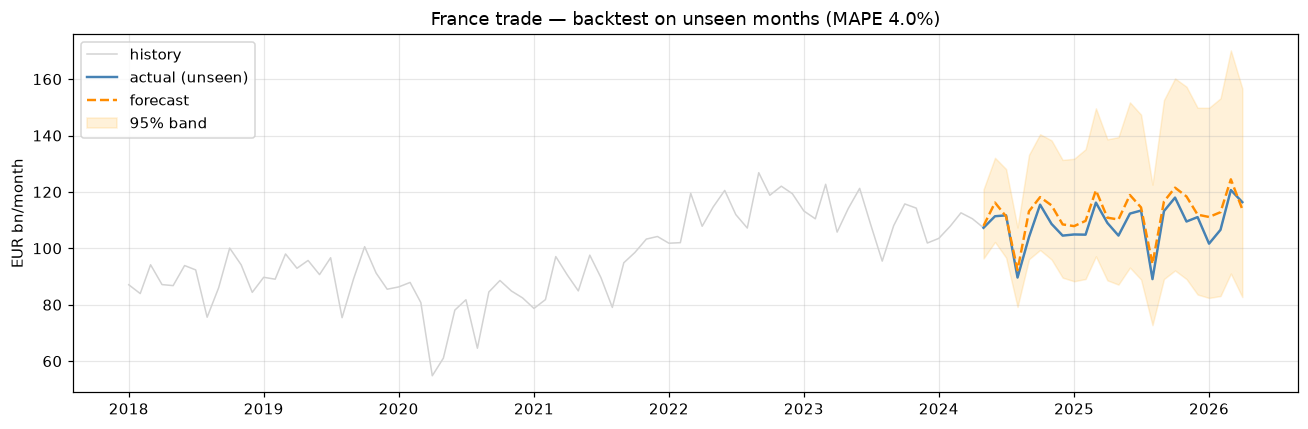

=> 100% of actuals fell inside the 95% band (well-calibrated ~ 95%).


In [2]:
bt = fc.backtest(fr, horizon=24, log=True)
print("Backtest (last 24 months, unseen):", bt)

fig, ax = plt.subplots(figsize=(12, 4))
hist = fr.loc["2018":]/1000
ax.plot(hist.index, hist, color="lightgrey", lw=1, label="history")
ax.plot(bt.actual.index, bt.actual/1000, color="steelblue", lw=1.6, label="actual (unseen)")
ax.plot(bt.pred.index, bt.pred/1000, color="darkorange", lw=1.6, ls="--", label="forecast")
ax.fill_between(bt.lower.index, bt.lower/1000, bt.upper/1000, color="orange", alpha=.15, label="95% band")
ax.set_title(f"France trade — backtest on unseen months (MAPE {bt.mape:.1f}%)")
ax.set_ylabel("EUR bn/month"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print(f"=> {bt.coverage:.0f}% of actuals fell inside the 95% band (well-calibrated ~ 95%).")

## Step 2 · Backtest ACROSS COVID — proving a shock is unpredictable

**What:** train only up to **end-2019**, then forecast into 2020–2021. **Why:** to show, honestly,
that no model can foresee a shock — and that this *is* the detection mechanism: the COVID actual
crashes **below the band**, so in real time it would be flagged the instant it printed.
**How to read:** where the blue actual leaves the shaded band = an anomaly the model could not have
predicted, but immediately detects.

/home/saizer/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/saizer/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


Backtest across COVID: MAPE=14.4%  RMSE=13,765  band-coverage=67%


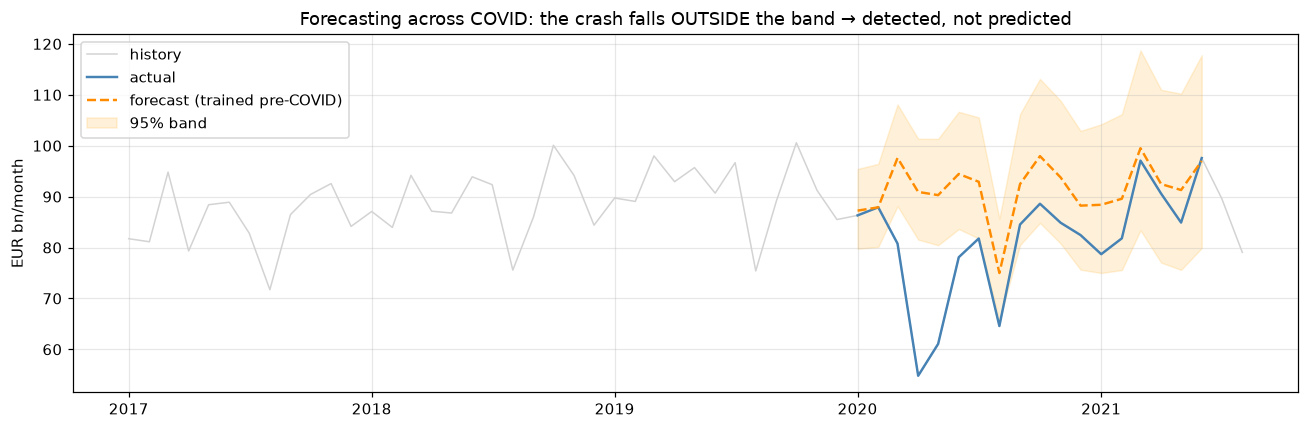

Months where the actual fell BELOW the 95% band: 6 -> these are the detectable anomalies.


In [3]:
btc = fc.backtest_from(fr, cutoff="2019-12-01", horizon=18, log=True)
print("Backtest across COVID:", btc)

fig, ax = plt.subplots(figsize=(12, 4))
ctx = fr.loc["2017":"2021-08"]/1000
ax.plot(ctx.index, ctx, color="lightgrey", lw=1, label="history")
ax.plot(btc.actual.index, btc.actual/1000, color="steelblue", lw=1.6, label="actual")
ax.plot(btc.pred.index, btc.pred/1000, color="darkorange", lw=1.6, ls="--", label="forecast (trained pre-COVID)")
ax.fill_between(btc.lower.index, btc.lower/1000, btc.upper/1000, color="orange", alpha=.15, label="95% band")
ax.set_title("Forecasting across COVID: the crash falls OUTSIDE the band → detected, not predicted")
ax.set_ylabel("EUR bn/month"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
below = (btc.actual < btc.lower).sum()
print(f"Months where the actual fell BELOW the 95% band: {below} -> these are the detectable anomalies.")

## Step 3 · Forecast to 2030 — the expected path + normal band

**What:** now refit on **all** data and project to December 2030. **Why:** with the model validated
(Step 1), the forward forecast is trustworthy *as a central path with growing uncertainty*.
**How to read:** the band widens with horizon — far-future months are genuinely uncertain.

/home/saizer/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/home/saizer/.local/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


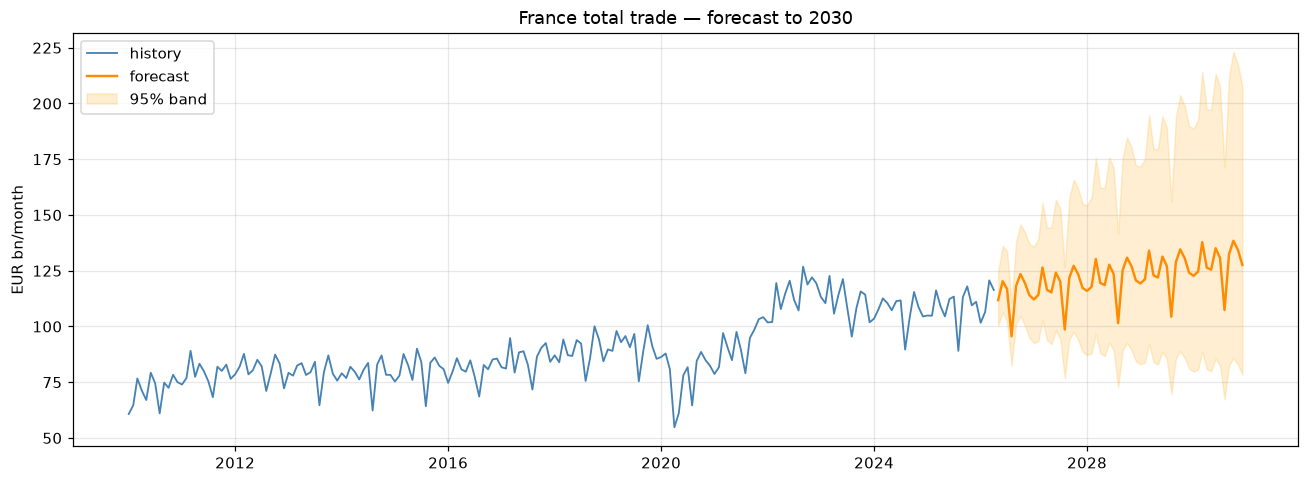

now (2026-04): EUR 116.4 bn  ->  central 2030-12: EUR 127.6 bn  (+10%)
95% band at 2030-12: EUR 78 - 208 bn (wide = far-future uncertainty).


In [4]:
f2030 = fc.forecast(fr, steps=56, log=True)          # 2026-05 .. 2030-12
fig, ax = plt.subplots(figsize=(12, 4.5))
hist = fr.loc["2010":]/1000
ax.plot(hist.index, hist, color="steelblue", lw=1.2, label="history")
ax.plot(f2030.mean.index, f2030.mean/1000, color="darkorange", lw=1.6, label="forecast")
ax.fill_between(f2030.lower.index, f2030.lower/1000, f2030.upper/1000, color="orange", alpha=.18, label="95% band")
ax.set_title("France total trade — forecast to 2030"); ax.set_ylabel("EUR bn/month")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

now, end = fr.iloc[-1]/1000, f2030.mean.iloc[-1]/1000
print(f"now (2026-04): EUR {now:.1f} bn  ->  central 2030-12: EUR {end:.1f} bn  ({(end/now-1)*100:+.0f}%)")
print(f"95% band at 2030-12: EUR {f2030.lower.iloc[-1]/1000:.0f} - {f2030.upper.iloc[-1]/1000:.0f} bn "
      f"(wide = far-future uncertainty).")

## Step 4 · Which countries are projected to grow most? ("potential increase")

**What:** rank all 27 countries by their log-trend slope (≈ %/year if the trend continues).
**Why:** answers "whose trade is set to increase fastest". **How to read:** longer bar = faster
projected growth. *Caveat:* trend extrapolation only — valid all-else-equal.

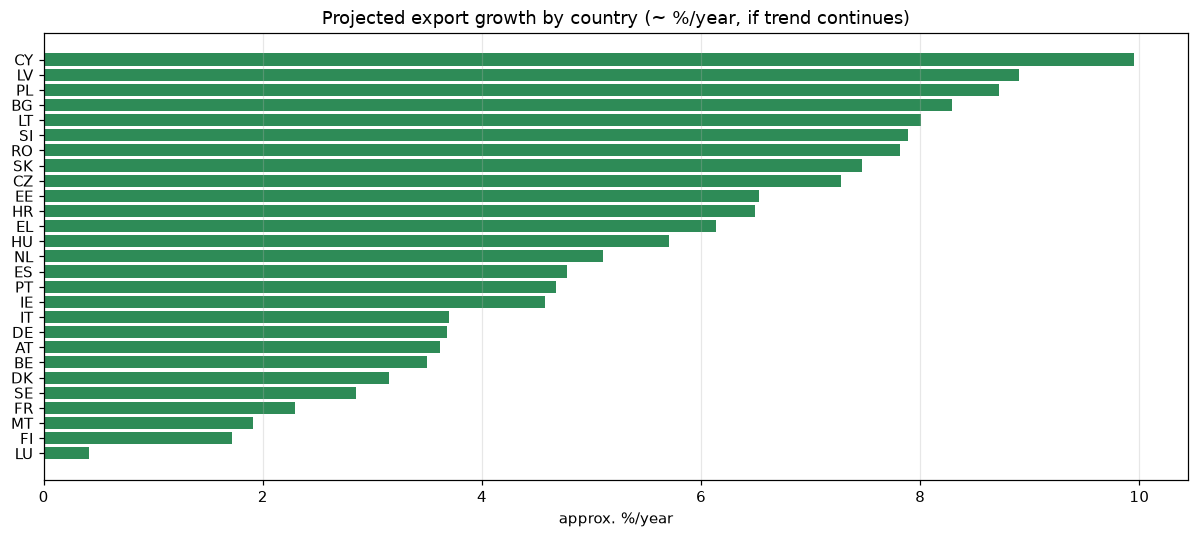

Top projected growers: {'LT': 8.0, 'BG': 8.3, 'PL': 8.7, 'LV': 8.9, 'CY': 9.9}


In [5]:
logged = pp.log_transform(df)
exp = [c for c in logged.columns if c.endswith("_EXP")]
proj = (an.trend_slopes(logged, exp) * 12 * 100); proj.index = [c[:2] for c in proj.index]
proj = proj.sort_values()

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(proj.index, proj.values, color="seagreen")
ax.set_title("Projected export growth by country (~ %/year, if trend continues)")
ax.set_xlabel("approx. %/year"); ax.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()
print("Top projected growers:", proj.tail(5).round(1).to_dict())

## Step 5 · Limitations (state these in the report)

- **Shocks are unpredictable.** Step 2 proved it — the model forecasts the *normal band*, not the
  crisis. Future anomalies are detected as band-breaks, not foreseen.
- **The band widens with horizon.** A 2030 point estimate has large uncertainty; treat the central
  line as a scenario, not a promise.
- **Structural breaks.** Brexit, sanctions, policy shifts can change the regime; the model assumes
  the past pattern continues.
- **Provisional recent data.** The last 1–2 months get revised, slightly affecting the latest fit.
- **Trend extrapolation (Step 4)** assumes constant growth — fine for ranking, not for precise levels.

## Step 6 · Summary

| Step | Result |
| --- | --- |
| Backtest (normal, 24 mo unseen) | low MAPE + ~95% band coverage → **it predicts, not memorises** |
| Backtest across COVID | crash falls outside the band → shocks are **detected, not predicted** |
| Forecast to 2030 | central path + widening band (the forward early-warning view) |
| Growth ranking | catch-up economies (CY, LV, PL, BG, LT) projected to grow fastest |

**→ Next: Notebook 07 · Query engine** — the exact-answer truth layer, then the interface + local LLM.